# MODULE 34 — SPEECH PROCESSING

# 34.7 Speech Feature Extraction 🎙️

Let's get into one of the most important parts of speech processing!

In the previous module, we learned how to prepare raw audio. Now we'll learn how to extract meaningful numerical information from that audio so machine-learning and deep-learning models can understand patterns in speech.

For example, two people might say the same word, but their voices differ in:

- Pitch and vocal characteristics.
- Loudness and energy.
- Speaking style.
- Frequency distribution.
- Pronunciation and articulation.

Speech feature extraction helps represent these characteristics numerically.

---

## 1. What is Speech Feature Extraction?

A microphone captures speech as a sequence of amplitude values called a waveform.

A raw waveform contains enormous amounts of information, but it doesn't directly describe useful properties such as energy, frequency distribution or spectral shape.

**Feature extraction** transforms the audio signal into numerical representations that make these properties easier to analyse.

![Spectrogram and STFT illustration](https://images.openai.com/static-rsc-4/iUlMArt50KDAlCgVSiZBs7Fp7n6gO_cRFvJz-tCgoVmPFEFrm3ba45sLw8GwmfkpUpE4xlqj0bZa3LZv89SEDJgrAlD1rweMng9pUL5lS1SmME28-UQRYDHK0B8biMT9TLfcoZRqVmT2F8DVih_es73IIUma1-S5B70YqCs0W_Q?purpose=inline)

![Filter banks and MFCC illustration](https://images.openai.com/static-rsc-4/17ioILQ7OVGhWyA-v7I7O4vlRQ5yATAJxzGrNNaU13Zv_fAbTWbIBSUrrPbNvy7jTg1U7TsAe4OQKu9doneM6buKvZYOySoglvAjhFIJlOogpj_ufYUdVYjqpAtKTlDCrer7OI35HdsFhwWO0jJgLGqbe0rXvtY2iPxgoN1mraEs?purpose=inline)

![Speech bandwidth illustration](https://images.openai.com/static-rsc-4/DOI_k70pPkIrU1rUChUrYIUDfA1SpKpl0jAe3ROc0lmx4W7XgjlwcTds7ui-RITIRku75CmxaieqUrMXqwip6uz5gnM_LXL6_4friKgjKbgy9cJdMd2q_UmOWHhKzVFnz9pbPMGcyZULn3vtu7qvu-TZVOwopA0zp6t7QKatSU4?purpose=inline)

### Basic pipeline

$$
\text{Speech Audio}
\rightarrow
\text{Feature Extraction}
\rightarrow
\text{Numerical Features}
\rightarrow
\text{ML/DL Model}
$$

For example:

- Speech recognition (ASR): Identify spoken words.
- Speech emotion recognition (SER): Identify emotions.
- Speaker recognition: Identify who is speaking.
- Speech analytics: Analyse speaking patterns.

An important point: features are usually extracted from short, overlapping frames rather than treating the entire recording as one signal. Speech characteristics change over time.

---

## 2. Time-Domain Features

Time-domain features are calculated directly from the waveform's amplitude values.

They help us understand how the signal behaves over time.

### 2.1 Mean Amplitude

Mean amplitude is the average of the waveform's sample values.

$$
\mu=\frac{1}{N}\sum_{n=1}^{N}x[n]
$$

Where:

- $x[n]$ = Amplitude of the $n^{th}$ sample.
- $N$ = Total number of samples.

**Example:**

Suppose our waveform is:

$$
x=[-2,-1,0,1,2]
$$

$$
\mu=\frac{-2-1+0+1+2}{5}=0
$$

Important: Mean amplitude can be close to zero because positive and negative waveform values cancel each other out.

Therefore, mean absolute amplitude is also useful:

$$
MAA=\frac{1}{N}\sum_{n=1}^{N}|x[n]|
$$

This tells us the average magnitude of the signal.

### 2.2 RMS Energy (Root Mean Square)

RMS measures the effective amplitude or strength of an audio signal.

$$
RMS=\sqrt{\frac{1}{N}\sum_{n=1}^{N}x[n]^2}
$$

**Why square the values?**

Because positive and negative amplitudes would otherwise cancel each other. Squaring makes all contributions positive.

**Example:**

$$
x=[-2,-1,1,2]
$$

$$
RMS=\sqrt{\frac{4+1+1+4}{4}}
$$

$$
RMS=\sqrt{2.5}
$$

$$
RMS\approx1.581
$$

**Applications:**

- Measuring speech loudness variation.
- Detecting silence or low-energy regions.
- Speech activity analysis.
- Emotion recognition, where vocal intensity can be informative.

### 2.3 Zero Crossing Rate (ZCR)

ZCR measures how frequently a signal changes sign from positive to negative or negative to positive.

$$
ZCR=\frac{1}{2N}
\sum_{n=1}^{N-1}
|\operatorname{sgn}(x[n])-\operatorname{sgn}(x[n+1])|
$$

Where the sign function is:

$$
\operatorname{sgn}(x)=
\begin{cases}
+1 & x>0\\
0 & x=0\\
-1 & x<0
\end{cases}
$$

**Intuition:**

- Low ZCR: Fewer sign changes, often associated with smoother or lower-frequency sounds.
- High ZCR: More sign changes, often associated with noisy or high-frequency sounds.

**Applications:**

- Speech versus silence analysis.
- Distinguishing some voiced and unvoiced sounds.
- Audio classification.

For example:

- Vowels generally have periodic, voiced waveforms.
- Sounds such as `/s/` are unvoiced and often have more irregular, high-frequency energy.

ZCR alone cannot reliably classify speech sounds.

### 2.4 Signal Energy

Signal energy measures the total squared amplitude of the signal.

$$
E=\sum_{n=1}^{N}x[n]^2
$$

Compare this with RMS:

| Feature | Formula | What it represents |
|---|---|---|
| Signal energy | $\sum x[n]^2$ | Total squared amplitude |
| RMS | $\sqrt{\frac{1}{N}\sum x[n]^2}$ | Effective amplitude |
| Mean amplitude | $\frac{1}{N}\sum x[n]$ | Average signed amplitude |
| Mean absolute amplitude | $\frac{1}{N}\sum |x[n]|$ | Average magnitude |

**Key distinction:** Signal energy increases with the number of samples, so comparing recordings of different lengths requires care. RMS is generally more convenient for comparing average signal strength.

---

## 3. Frequency-Domain Features

Time-domain features describe amplitude behaviour. But speech also contains important information about its frequency composition.

For example, vowels have characteristic resonant frequency patterns called **formants**. Frequency-domain analysis helps us study the distribution of energy across frequencies.

We commonly use the Short-Time Fourier Transform (STFT).

$$
X(m,k)=
\sum_{n=0}^{N-1}
x[n+mH]w[n]e^{-j2\pi kn/N}
$$

Where:

- $m$ = Frame index.
- $k$ = Frequency bin.
- $H$ = Hop length.
- $w[n]$ = Window function.
- $N$ = Frame length.

The STFT converts short portions of the waveform into frequency information.

### 3.1 Spectral Centroid

The spectral centroid represents the centre of mass of the magnitude spectrum.

$$
C_t=
\frac{\sum_k f_k|X_t[k]|}
{\sum_k|X_t[k]|}
$$

Where:

- $f_k$ = Frequency of bin $k$.
- $|X_t[k]|$ = Magnitude at that frequency.

**Intuition:** It tells us where the spectral energy is concentrated.

- Higher centroid: Often sounds brighter or sharper.
- Lower centroid: Often sounds darker or deeper.

![Spectral centroid illustration](https://images.openai.com/static-rsc-4/34Ws6LSQ5_hxBmqdjJq7AM6Wn8kP9Yo7eVUcavTHqIsNRzl0WEz0xte_SrMQIVXigdwxKBHYrvHM_-3TJyNNgkqqi4Vs8AEdvmbJjDmXQM4pCs44UVoP_P8vqpdli458kgbq1_b74m8TmARMQ0GeYE0S6IeYif9JsbobukVHaTA?purpose=inline)

Source: [Audio Feature Extraction — Devopedia](https://devopedia.org/audio-feature-extraction)

**Applications:**

- Speech characterization.
- Audio classification.
- Distinguishing different sound textures.

### 3.2 Spectral Bandwidth

Spectral bandwidth measures how spread out the frequency content is around the spectral centroid.

A common second-moment definition is:

$$
BW_t=
\sqrt{
\frac{
\sum_k(f_k-C_t)^2|X_t[k]|
}{
\sum_k|X_t[k]|
}
}
$$

- Higher bandwidth: Frequency content is more spread out.
- Lower bandwidth: Frequency content is more concentrated.

### 3.3 Spectral Rolloff

Spectral rolloff identifies the frequency below which a specified percentage of the total spectral magnitude is concentrated.

For example, with an 85% rolloff:

$$
\sum_{f_k\leq R_t}|X_t[k]|
\geq
0.85\sum_k|X_t[k]|
$$

The value $R_t$ is the rolloff frequency.

It helps describe how much high-frequency content exists in the signal.

### 3.4 Spectral Contrast

Spectral contrast measures the difference between spectral peaks and valleys within different frequency bands.

$$
SC=\text{Peak Energy}-\text{Valley Energy}
$$

In practice, implementations often calculate this difference in the decibel domain.

**Intuition:**

- High contrast: Prominent peaks and valleys in a frequency band.
- Low contrast: A relatively flat spectral distribution.

Applications include audio classification and distinguishing different sound characteristics.

### 3.5 Spectral Flux

Spectral flux measures how much the spectrum changes between consecutive frames.

One common definition uses the positive spectral differences:

$$
Flux_t=
\sum_k
\left(
\max(0,|X_t[k]|-|X_{t-1}[k]|)
\right)^2
$$

It indicates changes in frequency content over time.

**Applications:**

- Detecting changes in speech sounds.
- Identifying transient events.
- Audio segmentation.

Remember: These spectral features are generally calculated frame by frame, producing a sequence of feature values over time.

---

## 4. Important Speech Features

Now let's move to the features used heavily in practical speech-processing systems.

### 4.1 Mel Scale

The human ear does not perceive frequency changes linearly.

For example, the perceived difference between 100 Hz and 200 Hz is not necessarily equivalent to the difference between 5,000 Hz and 5,100 Hz.

The Mel scale is a perceptual frequency scale designed to approximate how humans perceive pitch.

A commonly used conversion is:

$$
Mel(f)=2595\log_{10}\left(1+\frac{f}{700}\right)
$$

Where $f$ is frequency in Hz.

![Mel scale and speech synthesis illustration](https://images.openai.com/static-rsc-4/PuKCGU_Qv5JdpnOuMNeazg5qkvkhTUh_77j8eMCx8pczIV6xHicsA4ij5eQ_f2rvbuPtHKTQldBxfMWmfE-VN5SZgdFLDE-OKr3sTyfbrU-FI0WkpuYMfzHciLxyeC2Yy8-zKGIScCmERW0UrrOfhtxnvc5zEfhbI1lciLrDvSI?purpose=inline)

Source: [Neural Architectures for Natural Speech Synthesis](https://mbrenndoerfer.com/writing/text-to-speech-neural-architectures-acoustic-modeling)

**Why is it useful in speech processing?**

- It provides finer frequency resolution at lower frequencies.
- It compresses the representation of higher frequencies.
- It creates a frequency representation more aligned with human auditory perception.

This is particularly useful because speech recognition needs to capture meaningful acoustic patterns rather than treating every frequency interval as equally important.

### 4.2 Mel Spectrogram

A normal spectrogram represents how signal energy is distributed across time and frequency.

A Mel spectrogram does something similar, but groups frequency information using Mel-spaced filters.

**How it is calculated:**

1. Divide the audio into short, overlapping frames.
2. Apply STFT to each frame.
3. Calculate the power spectrum.
4. Pass the spectrum through a Mel filterbank.
5. Combine the energy within each Mel filter.

$$
S_{Mel}(m,t)=
\sum_k H_m(k)|X(k,t)|^2
$$

Where:

- $H_m(k)$ = $m^{th}$ Mel filter.
- $X(k,t)$ = STFT of the audio.
- $S_{Mel}(m,t)$ = Energy in the Mel band.

![Mel spectrogram and ASR illustration](https://images.openai.com/static-rsc-4/nlfLS64h2hJ4WowuO_Ys_pk98hhvZ-RmmAMjHcTkDdd02tBhuV7OOwjKqX4ZC6z10ifYlRDPnlOacwp2flvIpu2dkOF4AMIdLzxNxPUWeLocm9EHf_7skwV4ZJeV-Z09LGyMGsI0ORbvXUqLE-2XV-Lo8z-3c5WRxtmJneEiTOE?purpose=inline)

Source: [NVIDIA NeMo — Automatic Speech Recognition](https://wandb.ai/aarora/Nvidia%20NeMO/reports/Train-Optimize-Analyze-Visualize-and-Deploy-Models-for-Automatic-Speech-Recognition-with-NVIDIA-s-NeMo--VmlldzoxNzI0ODEw)

The result is a two-dimensional representation:

- X-axis: Time.
- Y-axis: Mel frequency bands.
- Colour intensity: Energy in each band.

**Applications:**

- Speech recognition.
- Speech emotion recognition.
- Speaker identification.
- Audio classification.

### 4.3 Log-Mel Spectrogram

A Mel spectrogram contains energy values. A Log-Mel spectrogram applies a logarithmic transformation to those values.

$$
LogMel(m,t)=
10\log_{10}(S_{Mel}(m,t)+\epsilon)
$$

Here, $\epsilon$ is a small positive value that prevents taking the logarithm of zero.

**Why use logarithms?**

- Compresses a wide range of energy values.
- Makes weaker spectral components easier to inspect.
- Better reflects the logarithmic nature of human loudness perception.
- Often provides a useful input representation for neural networks.

**Important distinction:** A Mel spectrogram is not automatically a Log-Mel spectrogram. The logarithmic transformation is an additional step.

### 4.4 Mel-Frequency Cepstral Coefficients (MFCC)

<badge color="success">Must Know</badge>

MFCCs are among the most widely used traditional features in speech processing.

They describe the broad spectral shape of speech using a compact set of coefficients.

![MFCC extraction and speech recognition illustration](https://images.openai.com/static-rsc-4/x9EYVEKW8f6smZQe-9LTyf1PqTQpvh4muqp06Ai2GLA_c2KsDL4ZHCNJhzQdAPXbMXdQJjztzfj_qAHWITGq0ST3pxRQ7FpmcncQsiQg5_48-cy2uUMGTf-KjSP_9pAc8dMGXEz9eAqi4VN8VUU41ZnnZKnvjdYdyBhOPxyiPpE?purpose=inline)

Source: [Enhanced Conformer-Based Speech Recognition](https://www.mdpi.com/2076-3417/14/24/11583)

**How MFCCs are calculated:**

The typical process is:

1. **Framing:** Divide audio into short frames.
2. **Windowing:** Apply a window function to reduce spectral leakage.
3. **Fourier transform:** Convert each frame into frequency information.
4. **Power spectrum:** Calculate spectral power.
5. **Mel filterbank:** Group frequency information into Mel bands.
6. **Logarithm:** Take the log of the Mel energies.
7. **DCT:** Apply the Discrete Cosine Transform to obtain MFCC coefficients.

Mathematically:

$$
MFCC_t=DCT(\log(E_{Mel,t}))
$$

Where $E_{Mel,t}$ represents Mel filterbank energies for frame $t$.

**What does DCT do here?**

The Discrete Cosine Transform converts the log-Mel energy values into a compact set of coefficients.

The lower-order coefficients generally describe the broad spectral envelope, while higher-order coefficients capture finer variations.

MFCCs are useful because they:

- Compress spectral information into fewer values.
- Capture characteristics of the vocal tract's spectral envelope.
- Provide useful acoustic representations for speech classification and recognition.
- Work well with traditional ML models such as SVMs, GMMs and other classifiers.

**Why does the vocal tract matter?**

When we speak, the vocal cords generate sound, and the vocal tract (throat, mouth and nasal cavity) shapes that sound. This shaping produces resonances called formants.

MFCCs capture information related to the broad spectral envelope, which is influenced by these vocal-tract resonances.

However, MFCCs are not a direct measurement of a person's vocal tract or identity. They are acoustic features derived from the signal.

### 4.5 Chroma Features

Chroma features represent the distribution of audio energy across 12 musical pitch classes:

$$
C,\ C\#,\ D,\ D\#,\ E,\ F,\ F\#,\ G,\ G\#,\ A,\ A\#,\ B
$$

Notes separated by an octave belong to the same pitch class.

For example:

- C3
- C4
- C5

All belong to the pitch class C.

![Chroma feature illustration](https://images.openai.com/static-rsc-4/uOXmD1wzMkKK8K02D7ucH1FTSFmlMNVewkKu88W_1EicVALciSsg07K94Fiegn1JEf-v22oHsJJmmDBWi816frVkyKEuzGjeGoKn1h7AZK4VWcAeKjXqZqNpo9MhdiaZNRTK0seX9ubmGtkMxwo38DziIf_pAXcAZzeq9EuoF1s?purpose=inline)

Source: [Audio Features — The GenAI Guidebook](https://ravinkumar.com/GenAiGuidebook/audio/audio_feature_extraction.html)

**Applications:**

- Music information retrieval.
- Music classification.
- Chord recognition.
- Audio matching.

Chroma is useful in audio analysis, but it is generally less central than MFCC and Log-Mel features for ordinary speech recognition.

---

## 5. Waveform vs Spectrogram vs Mel Spectrogram vs MFCC

This distinction is extremely important. All four represent the same audio from different perspectives.

![Waveform and spectrogram illustration](https://images.openai.com/static-rsc-4/iUlMArt50KDAlCgVSiZBs7Fp7n6gO_cRFvJz-tCgoVmPFEFrm3ba45sLw8GwmfkpUpE4xlqj0bZa3LZv89SEDJgrAlD1rweMng9pUL5lS1SmME28-UQRYDHK0B8biMT9TLfcoZRqVmT2F8DVih_es73IIUma1-S5B70YqCs0W_Q?purpose=inline)

![Mel spectrogram example](https://images.openai.com/static-rsc-4/nlfLS64h2hJ4WowuO_Ys_pk98hhvZ-RmmAMjHcTkDdd02tBhuV7OOwjKqX4ZC6z10ifYlRDPnlOacwp2flvIpu2dkOF4AMIdLzxNxPUWeLocm9EHf_7skwV4ZJeV-Z09LGyMGsI0ORbvXUqLE-2XV-Lo8z-3c5WRxtmJneEiTOE?purpose=inline)

![MFCC and filterbank illustration](https://images.openai.com/static-rsc-4/17ioILQ7OVGhWyA-v7I7O4vlRQ5yATAJxzGrNNaU13Zv_fAbTWbIBSUrrPbNvy7jTg1U7TsAe4OQKu9doneM6buKvZYOySoglvAjhFIJlOogpj_ufYUdVYjqpAtKTlDCrer7OI35HdsFhwWO0jJgLGqbe0rXvtY2iPxgoN1mraEs?purpose=inline)

| Representation | What it shows | Axes / structure |
|---|---|---|
| Waveform | Amplitude changes over time | Time × amplitude |
| Spectrogram | Frequency content changes over time | Time × frequency |
| Mel spectrogram | Frequency content on Mel scale | Time × Mel bands |
| MFCC | Compact representation of log-Mel spectral shape | Time × coefficients |

A simple way to remember:

- **Waveform:** What is the amplitude doing?
- **Spectrogram:** What frequencies are present?
- **Mel spectrogram:** What frequencies are present on a perceptual scale?
- **MFCC:** What is the compact spectral shape of each frame?

### How do these features represent vocal characteristics?

| Vocal characteristic | Potentially useful features |
|---|---|
| Loudness / intensity | RMS, signal energy |
| Brightness / sharpness | Spectral centroid |
| Frequency spread | Spectral bandwidth |
| Spectral shape | MFCC, Mel spectrogram |
| Changes in sound | Spectral flux |
| Voiced / unvoiced patterns | ZCR, spectral features |
| Pitch-related information | Fundamental frequency (F0), pitch features |

One important distinction: pitch (F0) is not the same as spectral centroid. Pitch relates to the fundamental frequency of voiced speech, while spectral centroid describes the centre of mass of the spectrum.

---

## 6. Practical Lab — Extract and Visualize Speech Features 🧪

Now let's implement everything using Python.

We'll use:

- `librosa` — Audio and feature extraction.
- `numpy` — Numerical operations.
- `matplotlib` — Visualization.
- `soundfile` — Audio loading.

Traditional feature extraction with Librosa generally runs on the CPU. You don't need CUDA for this lab.

### 6.1 Install libraries

```bash
pip install librosa numpy matplotlib soundfile
```

### 6.2 Load the audio

Use a speech recording in WAV format. We'll convert it to mono and resample it to 16 kHz for this demonstration.

```python
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

audio_path = "speech.wav"

audio, sr = librosa.load(
    audio_path,
    sr=16000,
    mono=True
)

print("Sample Rate:", sr)
print("Audio Duration:", len(audio) / sr, "seconds")
print("Number of Samples:", len(audio))
```

### 6.3 Extract the waveform

```python
plt.figure(figsize=(14, 4))

librosa.display.waveshow(
    audio,
    sr=sr
)

plt.title("Speech Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()
```

This displays amplitude variation over time.

### 6.4 Extract the spectrogram

First, calculate the Short-Time Fourier Transform.

```python
n_fft = 1024
hop_length = 256

stft = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length
)

magnitude = np.abs(stft)

spectrogram_db = librosa.amplitude_to_db(
    magnitude,
    ref=np.max
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    spectrogram_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Speech Spectrogram")
plt.show()
```

**What should you observe?**

- Horizontal patterns represent frequency components that persist over time.
- Vertical changes indicate rapid changes in the sound.
- Vowels often show visible harmonic structures.
- Unvoiced sounds often appear more noise-like.

### 6.5 Extract the Mel spectrogram

```python
mel_spec = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=40,
    power=2.0
)

mel_spec_db = librosa.power_to_db(
    mel_spec,
    ref=np.max
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_spec_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.show()
```

Here, `n_mels=40` means that we use 40 Mel frequency bands.

You can experiment with 40, 64, 80 or 128 Mel bands. The appropriate choice depends on the model and task.

### 6.6 Extract MFCC

```python
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=13,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=40
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mfcc,
    sr=sr,
    hop_length=hop_length,
    x_axis="time"
)

plt.colorbar()
plt.title("MFCC Features")
plt.ylabel("MFCC Coefficients")
plt.show()

print("MFCC Shape:", mfcc.shape)
```

**Why `n_mfcc=13`?**

Thirteen coefficients are a common traditional MFCC configuration. It is not a universal requirement. Some systems use more coefficients, and some also calculate delta and delta-delta coefficients.

Understanding the output shape:

```text
(13, number_of_frames)
```

- 13 rows represent MFCC coefficients.
- Columns represent consecutive audio frames.

This means MFCCs form a sequence of feature vectors, not just one vector for the entire recording.

### 6.7 Extract RMS Energy

```python
rms = librosa.feature.rms(
    y=audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

plt.figure(figsize=(14, 4))

plt.plot(
    librosa.frames_to_time(
        np.arange(len(rms)),
        sr=sr,
        hop_length=hop_length
    ),
    rms
)

plt.title("RMS Energy")
plt.xlabel("Time (seconds)")
plt.ylabel("RMS")
plt.show()
```

Observe how RMS changes as the speaker talks, pauses and changes vocal intensity.

### 6.8 Extract Zero Crossing Rate

```python
zcr = librosa.feature.zero_crossing_rate(
    audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

plt.figure(figsize=(14, 4))

plt.plot(
    librosa.frames_to_time(
        np.arange(len(zcr)),
        sr=sr,
        hop_length=hop_length
    ),
    zcr
)

plt.title("Zero Crossing Rate")
plt.xlabel("Time (seconds)")
plt.ylabel("ZCR")
plt.show()
```

Compare the ZCR plot with RMS. Regions with different speech sounds may have different energy and zero-crossing patterns.

### 6.9 Extract the remaining spectral features

Librosa provides implementations for the other spectral features too.

```python
spectral_centroid = librosa.feature.spectral_centroid(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

spectral_bandwidth = librosa.feature.spectral_bandwidth(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

spectral_rolloff = librosa.feature.spectral_rolloff(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

spectral_contrast = librosa.feature.spectral_contrast(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)

spectral_flux = librosa.onset.onset_strength(
    y=audio,
    sr=sr,
    hop_length=hop_length
)

print("Centroid:", spectral_centroid.shape)
print("Bandwidth:", spectral_bandwidth.shape)
print("Rolloff:", spectral_rolloff.shape)
print("Contrast:", spectral_contrast.shape)
print("Flux:", spectral_flux.shape)
```

**Note:** `librosa.onset.onset_strength()` provides a spectral-flux-like onset-strength measure; it is not necessarily identical to every mathematical definition of spectral flux.

### 6.10 Extract Chroma features

```python
chroma = librosa.feature.chroma_stft(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    chroma,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="chroma"
)

plt.colorbar()
plt.title("Chroma Features")
plt.show()
```

This produces 12 pitch-class feature bands.

---

## 7. How the Extracted Features Are Used in ML/DL

Suppose you extract MFCCs from a 5-second speech recording.

Your output might have this shape:

```text
(13, 313)
```

This is a sequence of 313 frames, each containing 13 coefficients.

Depending on the model, you can use this representation in different ways:

| Model | Possible input |
|---|---|
| SVM | Aggregated MFCC statistics |
| Random Forest | Mean, standard deviation and other summary features |
| CNN | Mel spectrogram or MFCC matrix |
| RNN / LSTM | Sequence of MFCC feature vectors |
| Transformer | Log-Mel or other frame-level acoustic features |

For example, a CNN can learn local time-frequency patterns from a Mel spectrogram, while an RNN can learn how MFCC features change over time.

### Important practical considerations

- Use the same sample rate and feature configuration consistently.
- Keep training and inference preprocessing identical.
- Do not mix feature matrices with different frame lengths without handling their dimensions.
- For variable-length recordings, use padding, masking or appropriate batching.
- Feature extraction parameters such as `n_fft`, `hop_length` and `n_mels` affect the resulting representation.

---

## 8. Quick Revision

| Feature | Main purpose | Importance in speech |
|---|---|---|
| Mean amplitude | Average signed amplitude | Basic signal analysis |
| RMS | Effective signal amplitude | High |
| ZCR | Sign changes | High |
| Signal energy | Total squared amplitude | High |
| Spectral centroid | Spectral brightness | Useful |
| Spectral bandwidth | Frequency spread | Useful |
| Spectral rolloff | Frequency distribution limit | Useful |
| Spectral contrast | Spectral peak-valley difference | Useful |
| Spectral flux | Spectral changes over time | Useful |
| Mel spectrogram | Perceptual frequency representation | Very high |
| MFCC | Compact spectral representation | Very high |
| Log-Mel spectrogram | Logarithmic Mel energy representation | Very high in modern systems |
| Chroma | 12 pitch classes | Less central for speech |

---

In [1]:
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf

audio_path = "sample-speech-1m.mp3"

audio, sr = librosa.load(
    audio_path,
    sr=16000,
    mono=True
)

print("Sample Rate:", sr)
print("Audio Duration:", len(audio) / sr, "seconds")
print("Number of Samples:", len(audio))

Sample Rate: 16000
Audio Duration: 60.0054375 seconds
Number of Samples: 960087


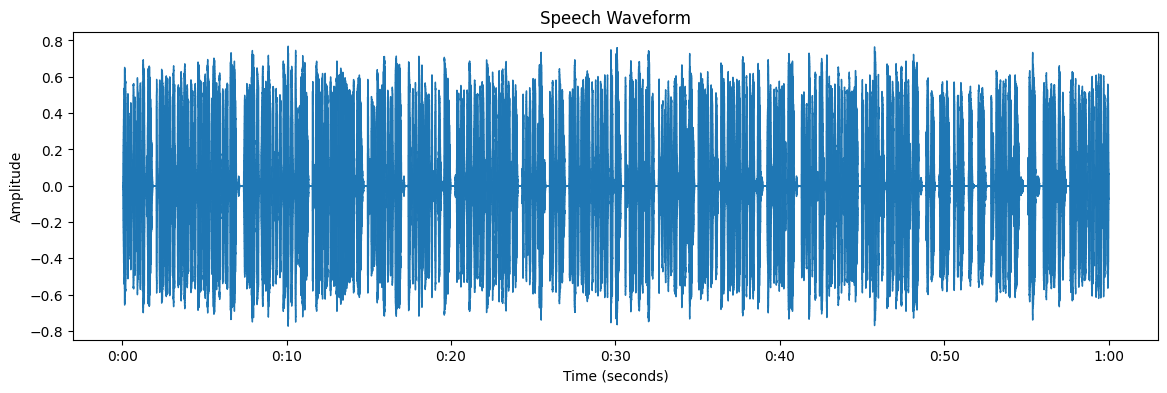

In [2]:
plt.figure(figsize=(14, 4))

librosa.display.waveshow(
    audio,
    sr=sr
)

plt.title("Speech Waveform")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.show()

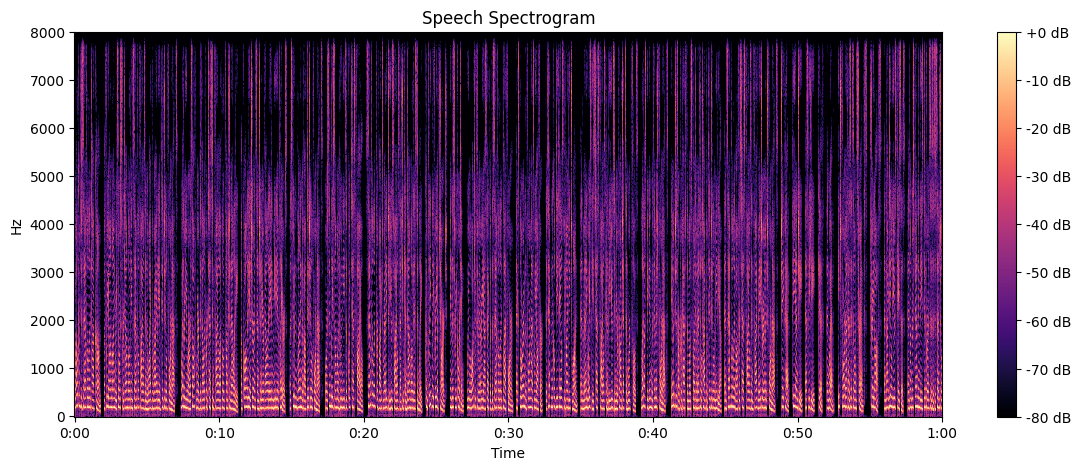

In [3]:
n_fft = 1024
hop_length = 256

stft = librosa.stft(
    audio,
    n_fft=n_fft,
    hop_length=hop_length
)

magnitude = np.abs(stft)

spectrogram_db = librosa.amplitude_to_db(
    magnitude,
    ref=np.max
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    spectrogram_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="hz"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Speech Spectrogram")
plt.show()

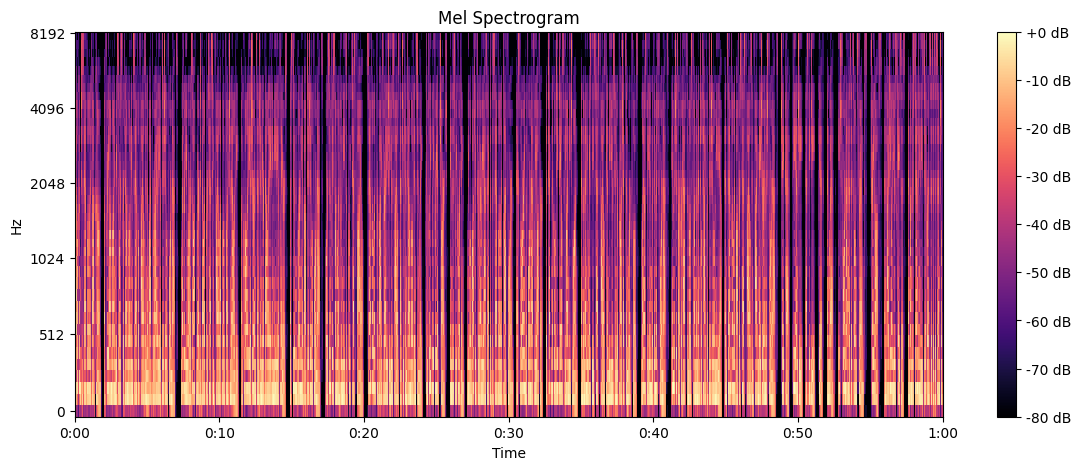

In [4]:
mel_spec = librosa.feature.melspectrogram(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=40,
    power=2.0
)

mel_spec_db = librosa.power_to_db(
    mel_spec,
    ref=np.max
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mel_spec_db,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="mel"
)

plt.colorbar(format="%+2.0f dB")
plt.title("Mel Spectrogram")
plt.show()

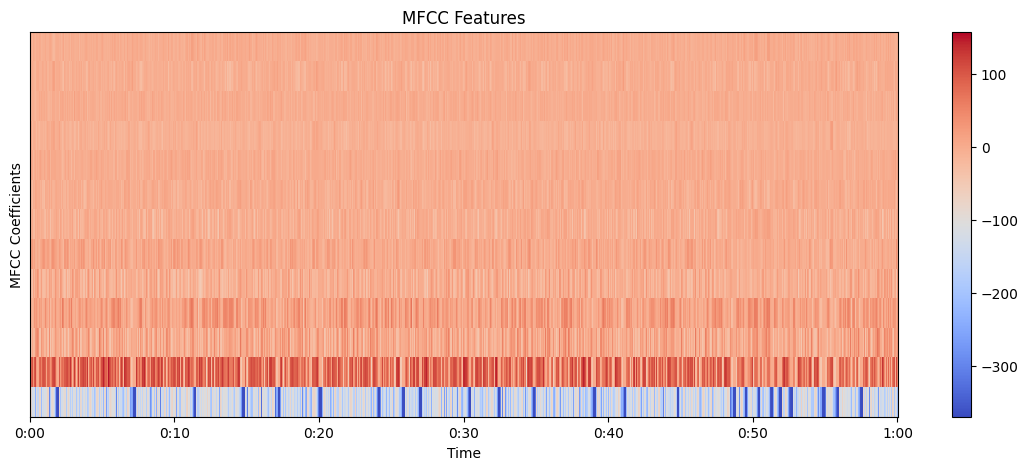

MFCC Shape: (13, 3751)


In [5]:
mfcc = librosa.feature.mfcc(
    y=audio,
    sr=sr,
    n_mfcc=13,
    n_fft=n_fft,
    hop_length=hop_length,
    n_mels=40
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    mfcc,
    sr=sr,
    hop_length=hop_length,
    x_axis="time"
)

plt.colorbar()
plt.title("MFCC Features")
plt.ylabel("MFCC Coefficients")
plt.show()

print("MFCC Shape:", mfcc.shape)

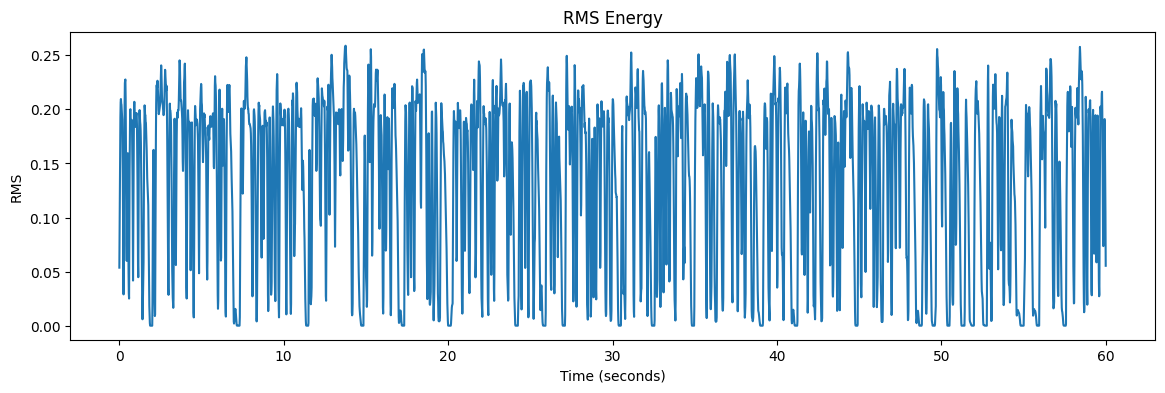

In [6]:
rms = librosa.feature.rms(
    y=audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

plt.figure(figsize=(14, 4))

plt.plot(
    librosa.frames_to_time(
        np.arange(len(rms)),
        sr=sr,
        hop_length=hop_length
    ),
    rms
)

plt.title("RMS Energy")
plt.xlabel("Time (seconds)")
plt.ylabel("RMS")
plt.show()

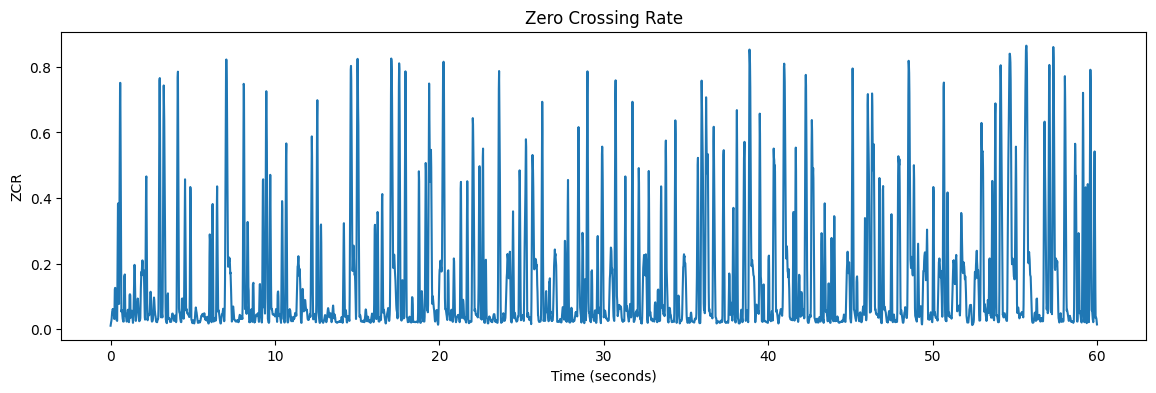

In [7]:
zcr = librosa.feature.zero_crossing_rate(
    audio,
    frame_length=n_fft,
    hop_length=hop_length
)[0]

plt.figure(figsize=(14, 4))

plt.plot(
    librosa.frames_to_time(
        np.arange(len(zcr)),
        sr=sr,
        hop_length=hop_length
    ),
    zcr
)

plt.title("Zero Crossing Rate")
plt.xlabel("Time (seconds)")
plt.ylabel("ZCR")
plt.show()

In [8]:
spectral_centroid = librosa.feature.spectral_centroid(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

spectral_bandwidth = librosa.feature.spectral_bandwidth(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

spectral_rolloff = librosa.feature.spectral_rolloff(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)[0]

spectral_contrast = librosa.feature.spectral_contrast(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)

spectral_flux = librosa.onset.onset_strength(
    y=audio,
    sr=sr,
    hop_length=hop_length
)

print("Centroid:", spectral_centroid.shape)
print("Bandwidth:", spectral_bandwidth.shape)
print("Rolloff:", spectral_rolloff.shape)
print("Contrast:", spectral_contrast.shape)
print("Flux:", spectral_flux.shape)

Centroid: (3751,)
Bandwidth: (3751,)
Rolloff: (3751,)
Contrast: (7, 3751)
Flux: (3751,)


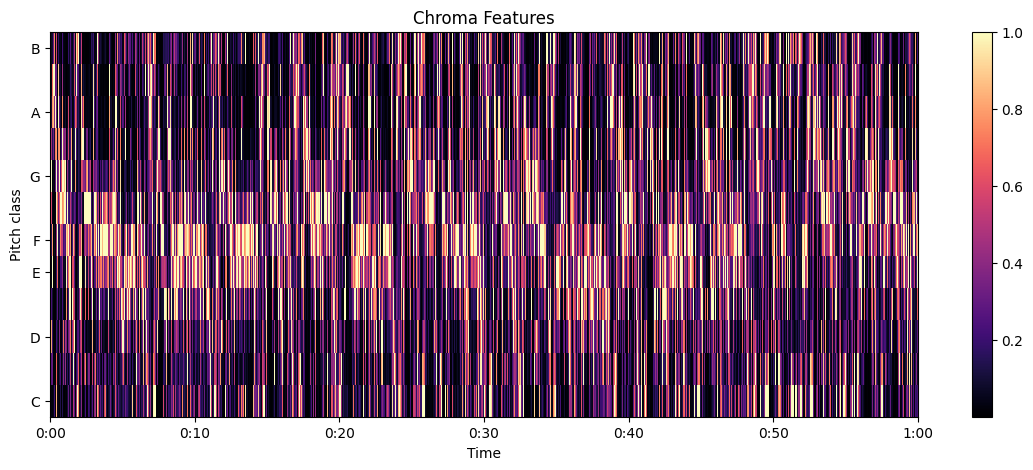

In [9]:
chroma = librosa.feature.chroma_stft(
    y=audio,
    sr=sr,
    n_fft=n_fft,
    hop_length=hop_length
)

plt.figure(figsize=(14, 5))

librosa.display.specshow(
    chroma,
    sr=sr,
    hop_length=hop_length,
    x_axis="time",
    y_axis="chroma"
)

plt.colorbar()
plt.title("Chroma Features")
plt.show()